# Yi-Ning Li
# USC ID: 6454654121
# Midterm

## 1a)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

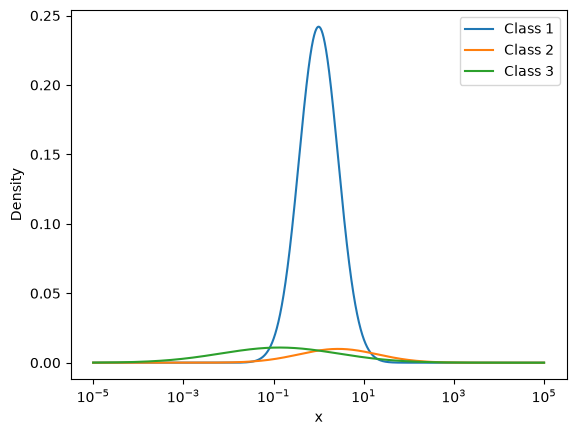

In [2]:
x=np.logspace(-5, 5, 10000)
sigma1=1
sigma2=2
sigma3=3
mu1=1
mu2=5
mu3=7

def lognormal_pdf(x, sigma, mu):
    return ( 1/(x*np.sqrt(2*np.pi)*sigma)*np.exp(-(np.log(x)-mu)**2/(2*sigma**2)) )

f1=lognormal_pdf(x, sigma1, mu1)
f2=lognormal_pdf(x, sigma2, mu2)
f3=lognormal_pdf(x, sigma3, mu3)

plt.plot(x, f1, label='Class 1')
plt.plot(x, f2, label='Class 2')
plt.plot(x, f3, label='Class 3')

plt.xscale('log')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.show()

In [3]:
classes=np.argmax(np.vstack([f1, f2, f3]), axis=0)+1
print(classes)


[3 3 3 ... 3 3 3]


In [4]:
changeIndex=np.where(np.diff(classes)!=0)[0]

for i in changeIndex:
    print(x[i], classes[i], '->', classes[i+1])

0.08248816435433749 3 -> 1
14.276293292992722 1 -> 2
901.1466645026293 2 -> 3


## 8) Student Performance

### a. Data Exploration and Pre-processing

#### i. Import as DataFrame

In [5]:
data=pd.read_csv('../data/student/student-mat.csv', sep=';')
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


#### ii. 

In [6]:
data=data[['age', 'studytime', 'schoolsup', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G3']]
data['schoolsup']=data['schoolsup'].map({'no': 0, 'yes': 1})
data['alc']=(data['Dalc']+data['Walc'])/2
data=data.drop(columns=['Dalc', 'Walc'])
display(data.head())
data.info()
display(data.describe())
display(data.isnull().sum())

,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5


<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        395 non-null    int64  
 1   studytime  395 non-null    int64  
 2   schoolsup  395 non-null    int64  
 3   goout      395 non-null    int64  
 4   health     395 non-null    int64  
 5   absences   395 non-null    int64  
 6   G3         395 non-null    int64  
 7   alc        395 non-null    float64
dtypes: float64(1), int64(7)
memory usage: 24.8 KB


,age,studytime,schoolsup,goout,health,absences,G3,alc
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,0.129114,3.108861,3.554430,5.708861,10.415190,1.886076
std,1.276043,0.839240,0.335751,1.113278,1.390303,8.003096,4.581443,0.992195
min,15.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000
25%,16.000000,1.000000,0.000000,2.000000,3.000000,0.000000,8.000000,1.000000
50%,17.000000,2.000000,0.000000,3.000000,4.000000,4.000000,11.000000,1.500000
75%,18.000000,2.000000,0.000000,4.000000,5.000000,8.000000,14.000000,2.500000
max,22.000000,4.000000,1.000000,5.000000,5.000000,75.000000,20.000000,5.000000


age          0
studytime    0
schoolsup    0
goout        0
health       0
absences     0
G3           0
alc          0
dtype: int64

#### iii. Outliers

Number of outliers: 

age :  1
studytime :  27
schoolsup :  51
goout :  0
health :  0
absences :  15
alc :  9


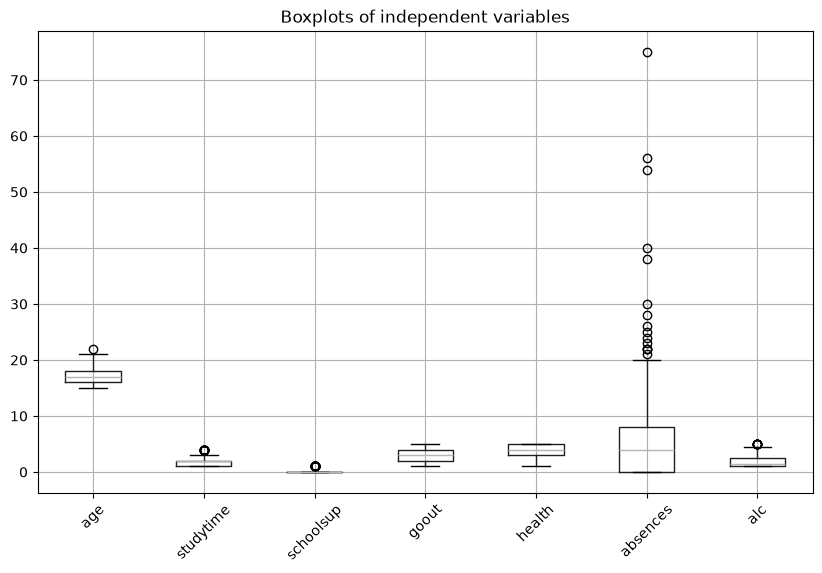

In [7]:
indepVars=['age', 'studytime', 'schoolsup', 'goout', 'health', 'absences', 'alc']
print('Number of outliers: \n')

for col in indepVars:
    Q1=data[col].quantile(0.25)
    Q3=data[col].quantile(0.75)
    IQR=Q3-Q1

    lowerBound=Q1-1.5*IQR
    upperBound=Q3+1.5*IQR

    outliers=data[(data[col]<lowerBound) | (data[col]>upperBound)]

    print(col, ': ', len(outliers))

data[indepVars].boxplot(figsize=(10, 6))
plt.xticks(rotation=45)
plt.title('Boxplots of independent variables')
plt.show()

#### iv. Standardization and PCA

In [8]:
X=data[indepVars]
y=data['G3']

scaler=StandardScaler()
XScaled=scaler.fit_transform(X)

pca=PCA(n_components=2)
XPca=pca.fit_transform(XScaled)

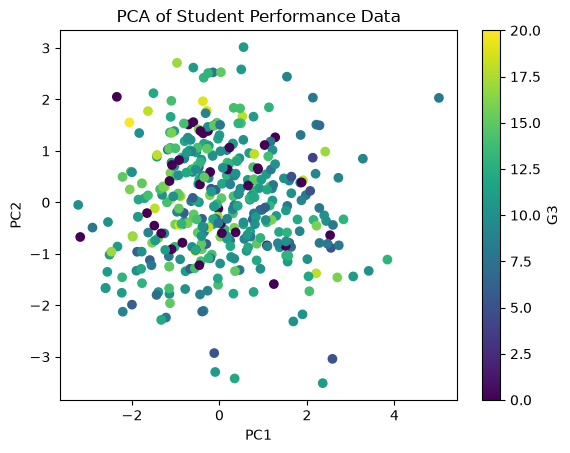

In [9]:
plt.scatter(XPca[:, 0], XPca[:, 1], c=y)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of Student Performance Data')
plt.colorbar(label='G3')
plt.show()

In [10]:
loadings=pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=indepVars)

loadings

,PC1,PC2
age,0.381940,0.589260
studytime,-0.329734,0.385671
schoolsup,-0.248184,-0.464202
goout,0.493755,-0.139613
health,0.080545,-0.400925
absences,0.280106,0.182798
alc,0.595871,-0.273677


PC1 is influenced most by alcohol consumption (alc) and going out (goout). PC2 is influenced most by age (age) and school support (schoolsup), since those have the largest respective PCA loadings. 

### b. Linear Regession

#### i. Split data

In [11]:
XTrain, XTest, yTrain, yTest=train_test_split(XScaled, y, test_size=0.2, random_state=552)

#### ii. Build models

In [12]:
linearModel=LinearRegression()
ridgeModel=Ridge(alpha=0.1)
lassoModel=Lasso(alpha=0.1)

linearModel.fit(XTrain, yTrain)
ridgeModel.fit(XTrain, yTrain)
lassoModel.fit(XTrain, yTrain)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


#### iii. Testing

In [13]:
linearPred=linearModel.predict(XTest)
ridgePred=ridgeModel.predict(XTest)
lassoPred=lassoModel.predict(XTest)

models={'Linear': linearPred, 'Ridge': ridgePred, 'Lasso': lassoPred}

for name, pred in models.items():
    mae=mean_absolute_error(yTest, pred)
    rmse=np.sqrt(mean_squared_error(yTest, pred))
    r2=r2_score(yTest, pred)

    print(name)
    print('MAE: ', mae)
    print('RMSE: ', rmse)
    print('R²: ', r2)
    print()

Linear
MAE:  3.4180089868486054
RMSE:  4.755811968114014
R²:  0.02817650947973449

Ridge
MAE:  3.4180620711578524
RMSE:  4.755859292625787
R²:  0.02815716838662463

Lasso
MAE:  3.447072936105375
RMSE:  4.7938401338163
R²:  0.012572688126561538



Best/lowest MAE: Linear Regression

Best/lowest RSME: Linear Regression

Best/highest R²: Linear Regression

#### iv. 
The R² values are all very low for all three models, from 0.01257 to 0.02818, meaning that the selected independent variables explain only a very small portion of the variation in the final grade G3. The Linear Regression and Ridge models explain about 2.82% of the variance, while the Lasso model explains about 1.26% of the variance. Therefore, these models have weak predictive power for G3 using the selected features. 

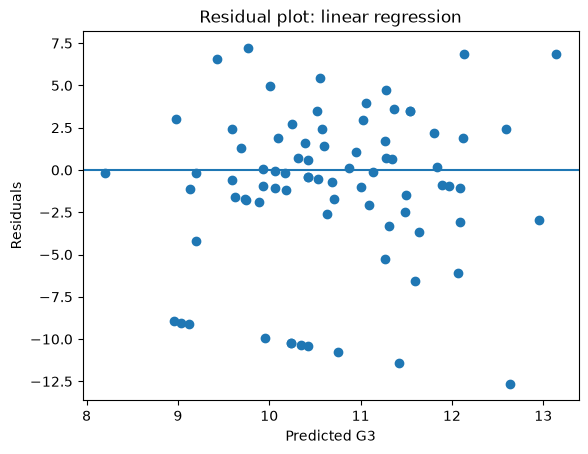

In [14]:
residuals=yTest-linearPred
plt.scatter(linearPred, residuals)
plt.axhline(y=0)
plt.xlabel('Predicted G3')
plt.ylabel('Residuals')
plt.title('Residual plot: linear regression')
plt.show()

#### v. Coefficients

In [15]:
coefTable=pd.DataFrame({'Variable': indepVars, 'Linear': linearModel.coef_, 'Ridge': ridgeModel.coef_, 'Lasso': lassoModel.coef_})
coefTable

,Variable,Linear,Ridge,Lasso
0,age,-0.781077,-0.780739,-0.630377
1,studytime,0.444812,0.444655,0.349092
2,schoolsup,-0.682472,-0.682191,-0.547461
3,goout,-0.582519,-0.582312,-0.485602
4,health,-0.243324,-0.243227,-0.141569
5,absences,0.192800,0.192695,0.072043
6,alc,0.037073,0.036909,-0.000000


In [16]:
print('Linear intercept: ', linearModel.intercept_)
print('Ridge intercept: ', ridgeModel.intercept_)
print('Lasso intercept: ', lassoModel.intercept_)

Linear intercept:  10.629377845616373
Ridge intercept:  10.629364682316378
Lasso intercept:  10.625104049478365


#### vi. 
negative: age, school support, going out, health

positive: study time, absences, alcohol consumption

Age, school support, going out, and health have negative relationships with G3, while study time, absences, and alcohol consumption have positive relationships. Study time has the strongest positive relationship, while age has the strongest negative relatioinship. Alcohol consumption has a coefficient very close to zero, which indicates little relationship with G3. 

#### vii. 
The 2 regularization methods Ridge and Lasso both regularize the regression coefficients, but Ridge shrinks coefficients toward zero without usually making them exactly zero, while Lasso can shrink some coefficients to exactly zero. In these results, Ridge performs almost identical to linear regression, but Lasso performs slightly worse and shrinks the alcohol coefficient to approximately zero. This suggests that regularization methods do not substantially improve prediction for this specific dataset, and some features may have limited predictive value. 

#### viii. 
If the regularization strength $\alpha$ is increased, the coefficients will shrink more. For Ridge, more coefficients get pushed closer to zero, and for Lasso, more coefficients may become exactly zero. If $\alpha$ is too large, however, the models may underfit, which can increase MAE and RMSE and decrease R². 

#### ix. 
Some feature engineering methods could be creating interaction terms between related variables, adding polynomial terms to capture nonlinear relationships, and transforming skewed variables. These engineered features may capture relationships with G3 that cannot be captured well with a linear model. 